# S05d: entry rules on the x10 exits

Pre-registration: [`S05d_README.md`](S05d_README.md). Same engine, signal and measured costs as S05c; all arms exit at s > +1.0 (long) / s < −1.0 (short).

| Arm | Entry |
|---|---|
| `t30` | abs(s) ≥ 3.0 |
| `pk` | excursion beyond 1.25 has peaked: abs(s) fell ≥ 0.25 from its peak, still abs(s) ≥ 1.25 |
| `t30pk` | as `pk`, but the excursion peak must have reached abs(s) ≥ 3.0 |

Reference (not judged): `x10` (S05c, entry abs(s) ≥ 1.25).

In [1]:
N_PLACEBO = 300              # per arm; alpha = 0.05 / 3 arms
N_JOBS = -1
PER_YEAR, WINDOW_S = 4, 3.0

import json, os, sys, time
from dataclasses import replace
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import __version__, s04, s05, s05b
from equity_trading.alpaca import ALPACA_VERSION, download_years, sample_quote_spreads
from equity_trading.data import vendor_dir, work_dir

SYNTHETIC = os.environ.get("S05_SYNTHETIC") == "1"
YEARS = list(range(2020, 2026))                      # 2026 not used
CFG = s05.S05Config(n_placebo=N_PLACEBO)
CFG = replace(CFG, close_long=1.0, close_short=-1.0)          # x10 exits for every arm
ARMS = {"t30": dict(open_long=-3.0, open_short=3.0), "pk": dict(entry_mode="peak", peak_open=1.25),
        "t30pk": dict(entry_mode="peak", peak_open=3.0), "x10": {}}
JUDGED = ["t30", "pk", "t30pk"]
ALPHA = 0.05 / len(JUDGED)
if SYNTHETIC:
    YEARS, N_PLACEBO = [2024, 2025], 10

tag = ("synthetic_" if SYNTHETIC else "") + f"alpaca{ALPACA_VERSION}_s05{s05.S05_VERSION}_p{s04.PANEL_VERSION}"
OUT = ROOT / "notebooks" / "Residual_Reversion" / ("05d_synthetic" if SYNTHETIC else "05d")
OUT.mkdir(parents=True, exist_ok=True)
CACHE = work_dir() / "results" / "s05d" / tag
CACHE.mkdir(parents=True, exist_ok=True)
QUOTE_CACHE = vendor_dir("Alpaca") / "quote_samples" / f"{CFG.timeframe}_w{WINDOW_S:g}s"
QUOTE_CACHE.mkdir(parents=True, exist_ok=True)
COL = {"t30": "#2a78d6", "pk": "#1baf7a", "t30pk": "#eb6834", "x10": "#8a8a84"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e3", "grid.linewidth": 0.6, "axes.titleweight": "bold", "font.size": 9})
if SYNTHETIC:
    from equity_trading.universe import SECTOR_ETF_01, UNIVERSE_01
    ETF_OF = {s: SECTOR_ETF_01[k] for k, v in UNIVERSE_01.items() for s in v}
    BENCH = "XLK"
else:
    constituents = pd.read_csv(ROOT / "src" / "equity_trading" / "reference" / "sp500_constituents_20260913.csv")
    ETF_OF = dict(zip(constituents["Symbol"], constituents["GICS Sector"].map(s05.SECTOR_ETF)))
    BENCH = "SPY"
STOCKS = sorted(ETF_OF)
ETFS = sorted(set(ETF_OF.values()))
print(f"synthetic={SYNTHETIC} | arms={ARMS} | placebos per arm={N_PLACEBO} | alpha={ALPHA:.4f}")

synthetic=False | arms={'t30': {'open_long': -3.0, 'open_short': 3.0}, 'pk': {'entry_mode': 'peak', 'peak_open': 1.25}, 't30pk': {'entry_mode': 'peak', 'peak_open': 3.0}, 'x10': {}} | placebos per arm=300 | alpha=0.0167


## 1. Data, measured costs, estimation (as S05b)

In [2]:
t0 = time.time()
if SYNTHETIC:
    panel, _ = s04.synthetic_ohlc_panel(YEARS)
else:
    download_years(STOCKS + ETFS + [BENCH], CFG.timeframe, YEARS, workers=8)
    panel = s04.cached_panel(STOCKS + ETFS + [BENCH], CFG.timeframe, YEARS, ffill_bars=CFG.ffill_bars)
have = set(panel.symbols)
TRADED = [s for s in STOCKS if s in have and ETF_OF[s] in have]
SC = np.array([panel.symbols.index(s) for s in TRADED])
EC = np.array([panel.symbols.index(ETF_OF[s]) for s in TRADED])
QUOTED = sorted(set(TRADED) | {ETF_OF[s] for s in TRADED})
SESSIONS = s05b.sample_sessions(YEARS, PER_YEAR, seed=42)
if SYNTHETIC:
    samples = pd.DataFrame([(s, 3e-4, 10, k, d) for d in SESSIONS for k in range(26) for s in QUOTED],
                           columns=["symbol", "half_spread", "n_quotes", "slot", "date"])
else:
    for d in [d for d in SESSIONS if not (QUOTE_CACHE / f"{d}.parquet").exists()]:
        sample_quote_spreads(QUOTED, d, s05b.slot_starts(YEARS, d), window_s=WINDOW_S, cache_dir=QUOTE_CACHE)
    samples = pd.concat([pd.read_parquet(QUOTE_CACHE / f"{d}.parquet") for d in SESSIONS], ignore_index=True)
H = s05b.cost_array(panel.index, panel.day_start, panel.symbols, s05b.cost_model(samples))
est_path = CACHE / "params.npz"
if est_path.exists():
    P = dict(np.load(est_path))
else:
    P = s05.estimate_all(panel, SC, EC, CFG, s05.first_decision_day(CFG)); np.savez(est_path, **P)
print(f"panel {panel.c.shape}, traded {len(TRADED)}, costs median {np.median(H[:, SC]) * 1e4:.2f} bps, ready in {time.time() - t0:.0f}s")

15Min: 0 batches to download (0 symbol-years), 8 parallel requests
panel (39064, 513), traded 501, costs median 3.01 bps, ready in 44s


## 2. Backtests (1×, 2×, 0× measured cost)

12 backtests in 1.3 min; trading starts 2020-02-03


,total_return,sharpe,max_drawdown,mean_daily,days
t30 1x,0.0891,0.3122,0.0938,0.0001,1486.0
t30 2x,-0.1010,-0.3176,0.1995,-0.0001,1486.0
t30 0x,0.3135,0.9191,0.0546,0.0002,1486.0
pk 1x,0.0545,0.2134,0.1028,0.0000,1486.0
pk 2x,-0.1339,-0.4524,0.2102,-0.0001,1486.0
pk 0x,0.2909,0.8895,0.0670,0.0002,1486.0
t30pk 1x,0.0594,0.2210,0.0880,0.0000,1486.0
t30pk 2x,-0.1185,-0.3912,0.1827,-0.0001,1486.0
t30pk 0x,0.2756,0.8343,0.0807,0.0002,1486.0
x10 1x,0.0987,0.3605,0.0782,0.0001,1486.0


,trades,mean_gross_bps,cost_per_trade_bps,median_bars,win_rate_gross,gross_over_cost,median_entry_abs_s,avg_open_positions,share_entries_0945
t30,15600.0,19.737,12.850,234.0,0.604,1.440,3.532,97.490,0.244
pk,16994.0,16.960,12.647,211.0,0.607,1.260,2.893,99.838,0.000
t30pk,15595.0,16.918,12.149,225.0,0.606,1.322,3.253,94.702,0.000
x10,16121.0,20.154,12.963,232.0,0.601,1.465,3.535,99.968,0.298


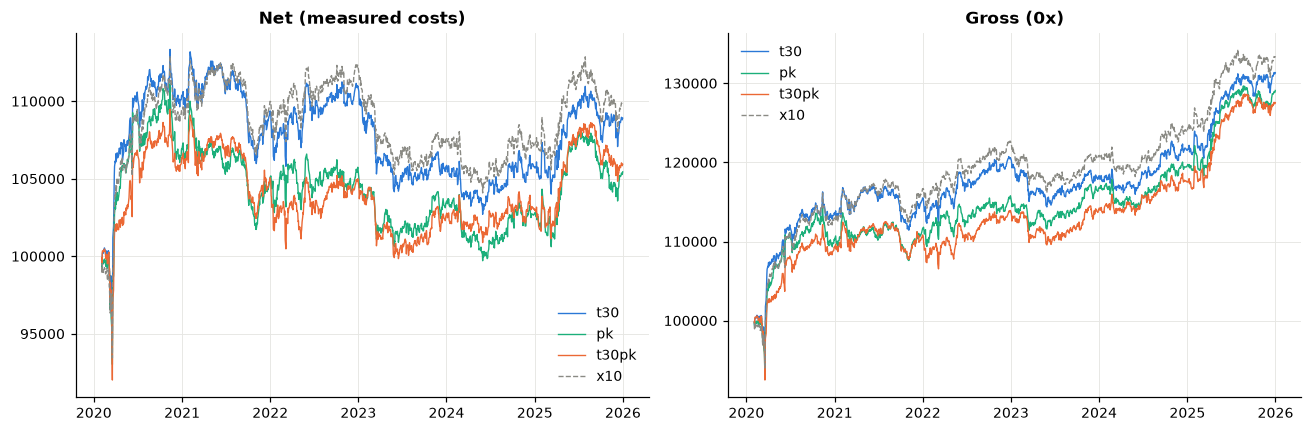

In [3]:
runs, rows, tstats = {}, {}, {}
t0 = time.time()
for arm, kw in ARMS.items():
    cfg_a = replace(CFG, **kw)
    for cm in (1.0, 2.0, 0.0):
        r = s05.backtest(panel, P, SC, EC, replace(cfg_a, cost_mult=cm), record=(cm == 1.0), half_spread=H)
        runs[(arm, cm)] = r
START = runs[("t30", 1.0)]["first_day"]
for (arm, cm), r in runs.items():
    rows[f"{arm} {cm:g}x"] = s04.perf_metrics(r["daily_equity"], CFG.initial_equity, START)
for arm in ARMS:
    tr = runs[(arm, 1.0)]["trades"]
    tstats[arm] = {"trades": len(tr), "mean_gross_bps": 1e4 * tr.gross_ret.mean(),
                   "cost_per_trade_bps": 1e4 * runs[(arm, 1.0)]["total_cost"] / tr.notional.sum(),
                   "median_bars": tr.bars.median(), "win_rate_gross": (tr.gross_pnl > 0).mean(),
                   "gross_over_cost": tr.gross_pnl.sum() / runs[(arm, 1.0)]["total_cost"],
                   "median_entry_abs_s": tr.s_entry.abs().median(),
                   "avg_open_positions": float(runs[(arm, 1.0)]["n_open"][panel.day_start[s05.first_decision_day(CFG) + 1]:].mean()),
                   "share_entries_0945": float((pd.DatetimeIndex(tr.entry_time).strftime("%H:%M") == "09:45").mean())}
    tr.drop(columns=["i"]).to_csv(OUT / f"trades_{arm}.csv", index=False, float_format="%.6g")
    runs[(arm, 1.0)]["daily_equity"].to_csv(OUT / f"daily_equity_{arm}.csv", header=["equity"], float_format="%.2f")
metrics = pd.DataFrame(rows).T
print(f"{len(runs)} backtests in {(time.time() - t0) / 60:.1f} min; trading starts {START.date()}")
display(metrics.round(4))
display(pd.DataFrame(tstats).T.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for arm in ARMS:
    for cm, axi in ((1.0, 0), (0.0, 1)):
        e = runs[(arm, cm)]["daily_equity"]; e = e[e.index >= START]
        ax[axi].plot(e.index, e, color=COL[arm], lw=0.9, label=arm, ls="--" if arm == "x10" else "-")
ax[0].set_title("Net (measured costs)"); ax[1].set_title("Gross (0x)")
for a in ax: a.legend(frameon=False)
plt.tight_layout(); plt.show()

## 3. Placebos per judged arm: random direction (same trades) and random contrarian timing (same exits)

In [4]:
from joblib import Parallel, delayed
rand_dir, ranks = {}, {}
for arm in JUDGED:
    cfg_a = replace(CFG, **ARMS[arm])
    base = runs[(arm, 1.0)]
    rand_dir[arm] = s05.random_direction_test(base["trades"].gross_pnl.to_numpy(), n=10_000, seed=CFG.seed)
    pl_path = CACHE / f"placebo_timing_{arm}_{N_PLACEBO}.parquet"
    if pl_path.exists():
        pl = pd.read_parquet(pl_path)
    else:
        t0 = time.time()
        pl = pd.DataFrame(Parallel(n_jobs=N_JOBS, batch_size=2, verbose=5)(
            delayed(s05.run_placebo)(panel, P, SC, EC, cfg_a, base["entry_rate"], CFG.seed * 1000 + i, START, H)
            for i in range(N_PLACEBO)))
        pl.to_parquet(pl_path); print(f"{arm}: {N_PLACEBO} placebos in {(time.time() - t0) / 60:.1f} min")
    pl.to_csv(OUT / f"placebo_timing_{arm}.csv", index=False, float_format="%.6g")
    bm = metrics.loc[f"{arm} 1x"]
    ranks[arm] = {k: s04.placebo_rank(bm[k], pl[k].to_numpy()) for k in ("total_return", "sharpe")}
display(pd.DataFrame(rand_dir).T.round(4))
display(pd.concat({a: pd.DataFrame(v).T for a, v in ranks.items()}).round(4))

[Parallel(n_jobs=-1)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=-1)]: Done  28 tasks      | elapsed:  1.1min


KeyboardInterrupt: 

## 4. Bootstrap, gates

In [ ]:
G, boots = {}, {}
for arm in JUDGED:
    e = runs[(arm, 1.0)]["daily_equity"]; e = e[e.index >= START]
    boots[arm] = {b: s04.block_bootstrap_mean(e.pct_change().dropna().to_numpy(), b, 10_000, CFG.seed) for b in (10, 20, 40)}
    G[arm] = s05.gates(boots[arm], rand_dir[arm], ranks[arm], metrics.loc[f"{arm} 2x"].to_dict(),
                       metrics.loc[f"{arm} 1x"].to_dict(), alpha=ALPHA)
display(pd.concat({a: pd.DataFrame(b, index=["mean", "lo95", "hi95"]).T for a, b in boots.items()}))
display(pd.DataFrame(G))
summary = {"study": "S05d", "synthetic": SYNTHETIC, "years": YEARS, "config": CFG.as_dict(), "arms": ARMS, "alpha": ALPHA,
           "trading_start": str(START.date()), "n_placebo_per_arm": N_PLACEBO, "metrics": metrics.to_dict(orient="index"),
           "trade_stats": tstats, "random_direction": rand_dir, "placebo_timing_ranks": ranks,
           "bootstrap": {a: {str(k): v for k, v in b.items()} for a, b in boots.items()}, "gates": G,
           "versions": {"package": __version__, "alpaca": ALPACA_VERSION, "s05": s05.S05_VERSION, "panel": s04.PANEL_VERSION}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
(OUT / "manifest.json").write_text(json.dumps({"files": sorted(p.name for p in OUT.iterdir()), "cache": str(CACHE)}, indent=2))
print(json.dumps({a: {k: g[k] for k in ["statistical_verdict", "economic_verdict", "verdict"]} for a, g in G.items()}, indent=2))